In [1]:
import os
import numpy as np
import tensorflow as tf
from glob import glob
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["image.interpolation"] = None

from dlutils.models.rdcnet import GenericRDCnetBase
from dlutils.models.heads import add_instance_seg_heads

from tifffile import imread

import json

from dlutils.dataset.dataset import parse_from_tfrecords

import tensorflow as tf
from dlutils.dataset.tfrecords import ImageToSegmentationRecordParser

# define labels colormap
vals = np.linspace(0,1,256)
np.random.shuffle(vals)
label_cmap = plt.cm.colors.ListedColormap(np.concatenate([[[0.,0.,0.,1.]],plt.cm.jet(vals)]))

# RDCnet
Recurrent Dialted Convolutional (RDC) network is a fully convolutional neural network architecture described [here](https://arxiv.org/abs/2010.00991). An RDCnet gets a raw image as input and predicts a semantic fore-/back-ground segmentation and an instance embedding for each pixel. These information are combined in a post-processing step to instance segmentations.

The following parameters define a RDCnet for 3D image data (Z, Y, X):

```
input_shape=(None, None, None, 1)
downsampling_factor=(1, 3, 3)
n_downsampling_channels=16
n_groups=4
channels_per_group=32
dilation_rates=(1, 2, 4)
dropout=0.1
n_steps=5
```
## Parameters
`input_shape`: Dimensionality of the image. Spatial diamensions are indicated by `None`. The last dimension is the number of input channels.

`downsampling_factor`: Downsampling factors used in the first layers of RDCnet. Increasing these numbers increases the receptive field of the network.

`n_downsampling_channels`: Number of channels used for downsampling. Increasing this number gives the network more capacity.

`n_groups`: Number of stacked dialted convolution blocks. Increasing this nubmer gives the network more capacity.

`channels_per_group`: Number of convolution channels per group. Increasing this number gives the network more capacity.

`dilation_rates`: Dilation factors for the dilated convolutions in the dilated convolution blocks. Adding more numbers increases the capacity and increasing the numbers increases the receptive field size.

`dropout`: Dropout rate of the RDCnet.

`n_steps`: Number of iterations the RDCblock is applied. Increasing this number increases the receptive field size.


## Receptive Field
The receptive field of a network describes how many pixels are aggregated by the neural network to make a decision on a given output pixel. It is recommended to have the training patch size being 1.5 times larger than the receptive field size. Usually the receptive field size should cover the structures which we are interested in segmenting. However, having too large receptive fields can also make training harder i.e. would require more training data. To estimate the receptive field size we can us the following fuction.

In [2]:
def receptive_field_rdcnet(downsampling_factor, dilation_rates, n_steps, img_size=512):
    """
    Creates a minimal RDCnet and applies it twice to an input image. The first time the image is all 
    zeros except for the center pixel and the second time the image is all zeros. Then the 
    two images are subtracted and all pixels which are different are part of the receptive field.
    """
    model = GenericRDCnetBase(input_shape=(None,None, None,1),
                              downsampling_factor=downsampling_factor,
                              n_downsampling_channels=1,
                              n_output_channels=4,
                              n_groups=1,
                              dilation_rates=dilation_rates,
                              channels_per_group=1,
                              n_steps=n_steps,
                              dropout=0.0)
    
    x = np.zeros((1, img_size, img_size, img_size, 1))

    x[0,img_size//2,img_size//2, img_size//2] = 1

    y = model.predict(x)
    y0 = model.predict(x * 0)
    
    rf = np.abs(y - y0) > 0
    rf = rf[0].sum(-1)

    d = np.where(rf.max((1,2)))
    h = np.where(rf.max((0,2)))
    w = np.where(rf.max((0,1)))
    
    return rf, d[0][-1] - d[0][0], h[0][-1] - h[0][0], w[0][-1] - w[0][0]

In [3]:
rf, d, h, w = receptive_field_rdcnet(downsampling_factor=(1,3,3),
                                     dilation_rates=(1, 2, 4),
                                     n_steps=5,
                                     img_size=512)

In [4]:
print('Receptive field size (Z, Y, X) = ({}, {}, {})'.format(d, h, w))
print('Recommended min-patch-size (Z, Y, X) = ({}, {}, {})'.format(int(d * 1.5), int(h * 1.5), int(w * 1.5)))

Receptive field size (Z, Y, X) = (44, 125, 125)
Recommended min-patch-size (Z, Y, X) = (66, 187, 187)


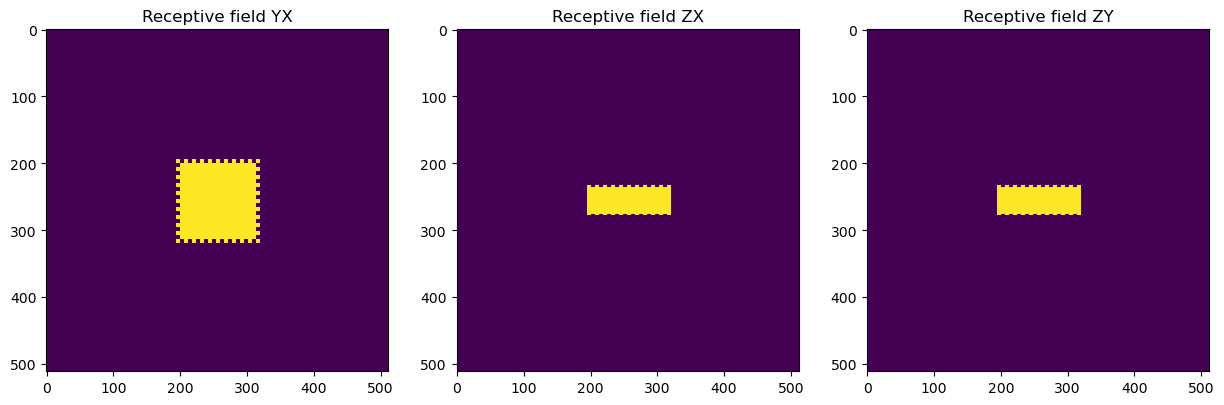

In [5]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(rf[rf.shape[0]//2])
plt.title('Receptive field YX')
plt.subplot(1,3,2)
plt.imshow(rf[:, rf.shape[1]//2])
plt.title('Receptive field ZX')
plt.subplot(1,3,3)
plt.imshow(rf[:,:, rf.shape[2]//2])
plt.title('Receptive field ZY')
plt.show()

# Inputs/Outputs
Here we want to take a look at the data which flows into the network and to what it is compared i.e. what the network is predicting. We know that we have to provide an input image `raw` and some ground truth (GT) annotations `labeling`. 

Over the next cells we will reconstruct what happens with the data processed by ISIT.

In [6]:
raw = imread('../../3d-cell-segmentation_data/raw_cell/200324NAR002AAA_210401_105120_B09_T0001F001L01A02Z01C02O00018.tif')

In [7]:
labeling = imread('../../3d-cell-segmentation_data/annot_cell/200324NAR002AAA_210401_105120_B09_T0001F001L01A02Z01C02O00018.tif')

In [8]:
print('raw: type = {}, shape = {}'.format(raw.dtype, raw.shape))
print('labeling: type = {}, shape = {}'.format(labeling.dtype, labeling.shape))

raw: type = uint16, shape = (54, 205, 199)
labeling: type = int16, shape = (54, 205, 199)


Additionally we have access to the `data_source.json` file which provides some additional meta data.

In [9]:
with open('../../3d-cell-segmentation_data/data_source.json', 'r') as f:
    data_source = json.load(f)

In [10]:
data_source

{'experiment_path': '',
 'mag': 60,
 'markers': {'2': 'ECAD'},
 'remarks': '60X with 2x binning',
 'spacing': [0.6, 0.216, 0.216],
 'timepoint': '999',
 'microscope': 'yokogawa',
 'wavelengths': {'2': 488},
 'annotator': 'nar'}

In [11]:
data_spacing = data_source['spacing']
print('Voxel size [Z, Y, X]: {}'.format(data_spacing))

Voxel size [Z, Y, X]: [0.6, 0.216, 0.216]


# Instance Record

If we want to train a new network we first define a new instance record. Such a record is built with the `BuildInstanceRecordTask` and is configurable with the following parameters in the `luigi.cfg` file:
```
[BuildInstanceRecordTask]
record_name=3D-cell-segmenation
seed=42
sample_group_keys=["fname"]
min_patch_size=(50, 200, 200)
patch_margins=(25, 50, 50)

train_fraction=0.8
valid_fraction=0.2
```

## Parameters

`record_name`: Name of the record.

`seed`: Random seed to have reproducable data shuffling.

`sample_group_keys`: File-path pattern keys according to which the samples are grouped. Usually we have a directory `raw` and `annot` containing files with the same name, which means we want to group them based on their file-name `fname` only.

`min_patch_size`: Minimum patch size which should be 1.5x larger than the receptive field.

`patch_margin`: Minimum distance between foreground labels and image border.

`train_fraction`: Fraction of image files used for training.

`valid_fraction`: Fraction of image files used for validation.

`model_spacing`: Voxel size for which the model should be trained.

## Processing

### Data splits
When a new instance record task is built the data is first split into three sub-records:
* train
* valid
* test

The number of files is based on the parameters `train_fraction` and `valid_fraction`. The test-fraction is computed by<br>
`test_fraction = 1 - train_fraction - valid_fraction`.

### Rescaling
The splitted data is then loaded and rescaled such that the voxel-size corresponds to the `model_spacing`. This is done by reading the `data_spacing` information from `data_source.json` and computing the corresponding scaling factors for each dimension. <br>
__Note:__ If we train a new model we will set the `model_spacing` to be equal to the `data_spacing` in `data_source.json`. However, if we want to apply or fine-tune a trained model we might have different values and this allows us to reuse models on differently sampled data.

### Normalizing
After the data is split and rescaled the input images are normalized to have zero mean and a standard deviation of one. This also converts the input data to float-type.

### Cropping
Finally the input images are cropped/extended such that all foreground annotations are `patch_margin` away from an image border. If a label is too close to an image border the image is extended. Furthermore the images are not cropped smaller than the `min_patch_size`. Again if an image is smaller than `min_patch_size` it gets extended. The extend mode is set to `reflect` i.e. the image is mirrored at the image border.

In [12]:
parser_fn =  ImageToSegmentationRecordParser(tf.float32,
                                       tf.int16,
                                       fixed_ndim=4).parse

In [13]:
dataset = parse_from_tfrecords('./training_outputs/complete_record_train.tfrec',
                                       parser_fn=parser_fn,
                                       num_parallel_calls=1)

In [14]:
sample = next(dataset.as_numpy_iterator())

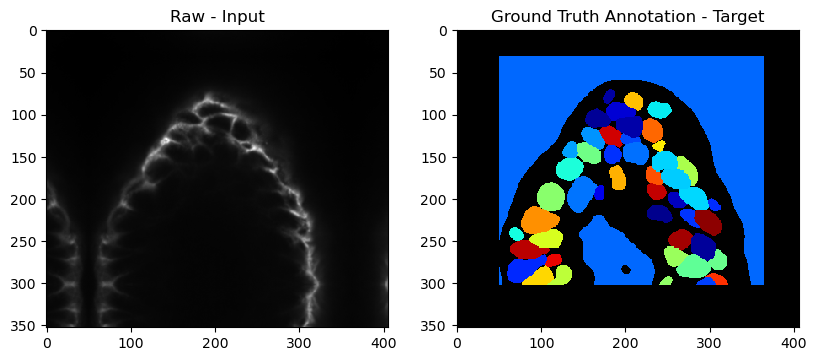

In [15]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(sample['image'][50,...,0], cmap='gray')
plt.title('Raw - Input')
plt.subplot(1,3,2)
plt.imshow(sample['segm'][50,...,0], cmap=label_cmap)
plt.title('Ground Truth Annotation - Target')
plt.show()

In the above ground truth background is shown in red and has `value = 0`. The black areas have `value = -1` and the instance segmentations (nuclei) have `value > 0`. In this labeling scheme pixels annotated with `value = -1` are ignored during the loss computation i.e. the network is not conditioned at all. This is useful if we don't know the label yet e.g. if we only have sparse cell annotations.

# Instance Model Record
If we want to train a RDCnet with a given instance record (training data) we can use the `InstanceModelExportTask`. This task has the following configureation:
```
[InstanceModelExportTask]
suffix=_3D-cell-seg
plot_dataset=true
# resume_weights=.../weights_latest.h5

# RDCnet parameters
input_shape=(None, None, None, 1)
downsampling_factor=(1,3,3)
n_downsampling_channels=16
n_groups=4
channels_per_group=32
dilation_rates=(1,2,4)
dropout=0.1
n_steps=5

# Data augmentations
augmentation_with_flips=true
augmentation_with_rot90=true
augmentation_gaussian_noise_sigma=0.03
augmentation_gaussian_noise_mu=0.03
augmentation_offset_sigma=2.
augmentation_intensity_scaling=(0.1, 10.)

# Loss settings
intra_margin=1
inter_margin=4
jaccard_hinge=0.3
jaccard_eps=0.1

# Training parameters
train_batch_size=1
valid_batch_size=1
train_batches_per_epoch=200
valid_batches=15
epochs=350
lr_max=0.0001
lr_min=0.000001
n_restarts=3
patience=200
patch_size=(50,200,200,1)
```

## Parameters
`suffix`: Suffix of the model name.

`plot_dataset`: Plot training data examples and output as `training_samples.pdf`.

`resume_weights`: If training should be continued or if we want to fine-tune a pre-trained model.

(RDCnet parameters are described above.)

`augmentation_with_flips`: Randomly flips the image data along axes.

`augmentation_with_rot90`: Randomly rotates the image data by multiples of 90 degrees.

`augmentation_gaussian_noise_sigma`: Sigma of additive Gaussian noise.

`augmentation_gaussian_noise_mu`: Mean of additive Gaussian noise.

`augmentation_offset_sigma`: Random intensity offset drawn from a Gaussian distribution with mean of zero.

`augmentation_intensity_scaling`: Random intensity rescaling.

`intra_margin`: Distance from an embedding to its center below which the loss is zero.

`inter_margin`: Distance from an embedding to other centers above which the loss is zero.

`jaccard_hinge`: Threshold over which pixels in prediction are replaced by the groundtruth (i.e. no backpropagation).

`jaccard_eps`: Epsilon to avoid divison by zero.

`train_batch_size`: Number of patches used to train on simultaneously. Increase this until your GPU runs out of memory (OOM).

`valid_batch_size`: Number of patches used to validate on simultaneously.

`train_batches_per_epoch`: Number of batches per epoch.

`valid_batches`: Number of batches used for validation after each epoch.

`epochs`: Number of training epochs.

`lr_max`: Maximum (starting) learning rate.

`lr_min`: Minimum learning rate. The learning rate is reduced from max to min following a cosine-annealing strategy.

`n_restarts`: Number of times the learning rate is reset to `lr_max`. The number of epochs to get to `lr_min` is doubled after each restart. 

`patience`: Number of epochs with no improvement after which training will be stopped.

`patch_size`: Size of the training patches. Should be at least 1.5 times larger than the receptive field.

This creates a new RDCnet, dataloaders and losses which are then run according to the training parameters. 


# Loss Computation
So far we have prepared the data for training into pairs of (`raw`, `labeling`) which are sufficenlty preprocessed. During training patches of size `patch_size` are randomly extracted and the augmentations are applied on the fly. Then the `raw` data is fed through the network which produces two outputs (i) `semantic segmentation` and (ii) `pixel embeddings`. On the `semantic segmentation` the Jaccard-Loss and on the `pixel embeddings` an Embedding-Loss is computed. Which means that our single `labeling` target has to be converted into two different targets. These targets are created from `labeling` as last augmentation step.

In [16]:
fg = tf.minimum(tf.cast(sample['segm'], tf.int32), 1)
fg = tf.squeeze(fg, axis=-1)
fg_hot = tf.one_hot(fg, depth=2)

targets ={
    'embeddings': sample['segm'],
    'semantic_class': fg_hot
}

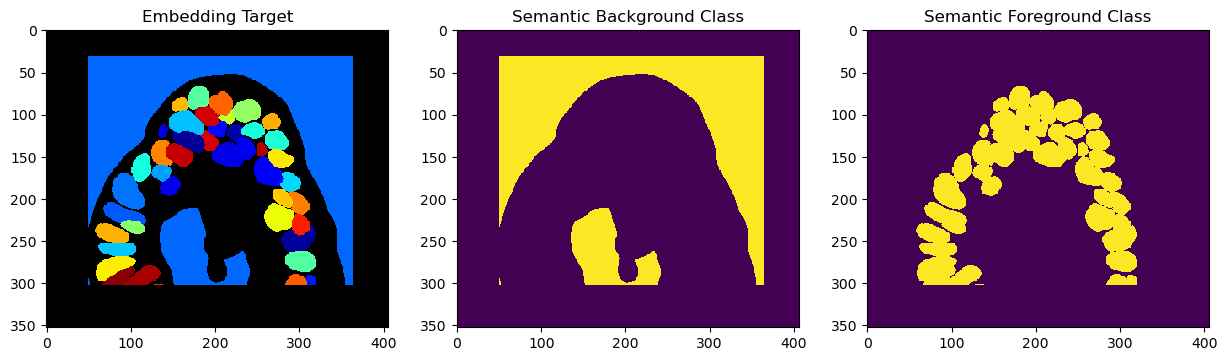

In [17]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(targets['embeddings'][56,...,0], cmap=label_cmap)
plt.title('Embedding Target')
plt.subplot(1,3,2)
plt.imshow(targets['semantic_class'][56,...,0])
plt.title('Semantic Background Class')
plt.subplot(1,3,3)
plt.imshow(targets['semantic_class'][56,...,1])
plt.title('Semantic Foreground Class')
plt.show()

__Note:__ The missing labels with `value = -1` in the ground truth is black in the embedding and both times inactive (dark blue) in the semantic classes. 

This information is used to compute the loss only for pixels where the GT label is not `value = -1`. In other words, the loss is only compute for regions for which we have an accurate GT and for regions where we don't know we can just pass `-1` and no harm will be done during training.

## Embedding Loss
The embedding loss is only compute on the foreground pixels i.e. only on the instance segmentations.

In [18]:
# Masking in the embeddings loss:
fg_mask = tf.cast(
            tf.reduce_any(tf.greater_equal(tf.cast(targets['embeddings'], tf.float32), 0.5),
                          axis=-1,
                          keepdims=True), tf.float32)

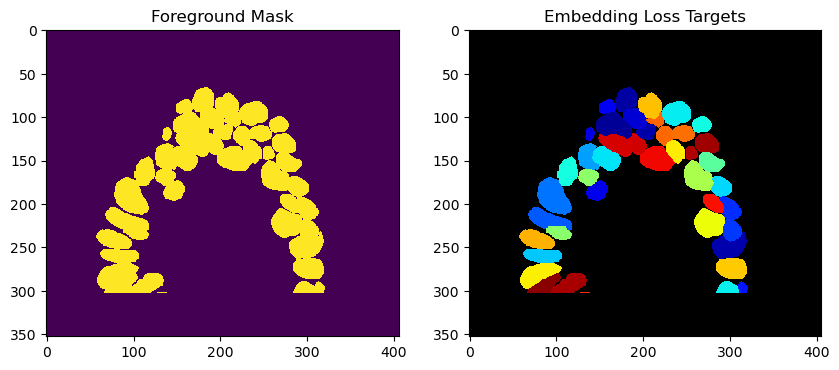

In [19]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(fg_mask[56,...,0])
plt.title('Foreground Mask')
plt.subplot(1,2,2)
plt.imshow(targets['embeddings'][56,...,0] * fg_mask[56,...,0], cmap=label_cmap)
plt.title('Embedding Loss Targets')
plt.show()

## Semantic Loss
The semantic loss is compute on foreground (`value = 1`) and background (`value = 0`) pixels but not on unknown (`value = -1`) pixels.

In [20]:
annot_mask = tf.cast(
            tf.reduce_any(tf.greater_equal(targets['semantic_class'], 0.5),
                          axis=-1,
                          keepdims=True), tf.float32)

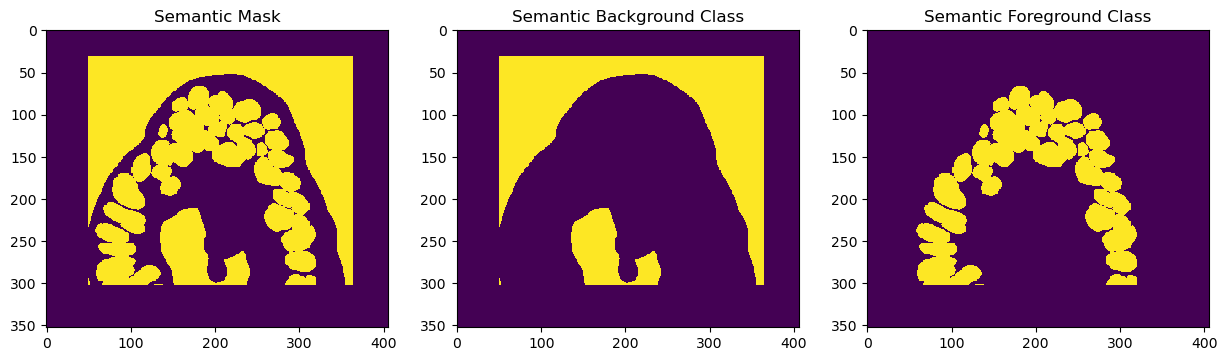

In [21]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(annot_mask[56,...,0])
plt.title('Semantic Mask')
plt.subplot(1,3,2)
plt.imshow(targets['semantic_class'][56,...,0] * annot_mask[56,...,0])
plt.title('Semantic Background Class')
plt.subplot(1,3,3)
plt.imshow(targets['semantic_class'][56,...,1] * annot_mask[56,...,0])
plt.title('Semantic Foreground Class')
plt.show()

# Final Notes
Using the ground truth labels with `value = -1` as unknown class is extremly helpful for us. Because we can still train a network even if we don't know the appropriate label for certain regions of the image. Some intuition would be that we correct/teach the network only about regions for which we know the truth and for the regions where we don't know we hope that it will figure something useful out. Ofcourse we can later on correct the predictions of such a network and eventually we want to eliminate all `value = -1` regions in our ground truth. 